**Metrics.** Accuracy, balanced accuracy, macro-F1 (headline), per-class recall, quadratic weighted kappa (QWK), log loss, and the confusion matrix.
Expected calibration error (ECE) is in the appendix only.

| Step | What it does |
|---|---|
| 0 | Data contract, split, shared harness, majority-class baseline |
| 1 | Softmax LR from scratch in numpy: gradient check, GD vs mini-batch SGD, match to sklearn |
| 2 | C sweep with 5 × 5 repeated CV (bias vs variance) |
| 3 | L1 vs L2 coefficient paths for the High class |
| 4 | Standardised coefficients, multicollinearity (VIF), permutation importance inside CV |
| 5 | Ordinal (proportional-odds) logit vs multinomial |
| 6 | Degree-2 polynomial features |
| 7 | Binary High-vs-rest margins; logistic vs hinge vs zero-one loss |
| 8 | Model choice by CV, final test evaluation, error rate by grade, marginal cases |
| A | Appendix: calibration (ECE) |

In [1]:
import os, glob, time, hashlib, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             cohen_kappa_score, log_loss, confusion_matrix)
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.miscmodels.ordinal_model import OrderedModel

# ---------------- Settings you may need to edit ----------------
FFNN_RED_CV_MACRO_F1 = None   # paste the FFNN pair's red-only 5x5 CV macro-F1 MEAN here (e.g. 0.60); None = skip the FFNN comparison
FFNN_RED_CV_STD = None        # and its standard deviation across the 25 folds, if they have it
SELECTION_RULE = "one_se"     # "one_se": simplest LR variant within one standard error of the best CV macro-F1
                              # "best_mean": the variant with the highest CV macro-F1, however small the lead
# ---------------------------------------------------------------

SEED = 42                                  # one seed for every random choice in the notebook
np.random.seed(SEED)                       # legacy global numpy RNG (used by some libraries)
rng = np.random.default_rng(SEED)          # our own generator for anything we sample ourselves
T_START = time.time()                      # to report total runtime at the end

N_SPLITS, N_REPEATS = 5, 5
# One CV object for the whole notebook. Because random_state is fixed, every model sees exactly the same
# 25 train/held-out folds, so fold-by-fold differences between models are fair (paired) comparisons.
RCV = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

DATA_DIR = "."                             # the CSV sits in the same folder as this notebook
SPLIT_FILE = "split_indices.npz"           # shared with the other pairs, also next to the notebook
RES, FIG = "results", "figures"            # output folders, created automatically
for d in (RES, FIG):
    os.makedirs(d, exist_ok=True)

# sklearn 1.8 deprecated `penalty=`; newer versions select L1/L2 through l1_ratio instead.
SK_NEW = tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 8)
def pen_kw(pen):
    """Keyword arguments that select an L1 or L2 penalty on any sklearn version."""
    if SK_NEW:
        return {"l1_ratio": 1.0 if pen == "l1" else 0.0}
    return {"penalty": pen}

# Plot style: recessive grid, no top/right spines, 150 dpi on save.
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.titlesize": 11})
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#b8b7b2"                           # de-emphasised series
CLASS_NAMES = np.array(["Low", "Medium", "High"])
CLASS_COLORS = dict(zip(CLASS_NAMES, PALETTE[:3]))

def savefig(fig, name):
    """Save a figure as figures/<name> at 150 dpi and return the path."""
    path = os.path.join(FIG, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path

def save_table(df, name, index=True):
    """Save a results table as results/<name>."""
    df.to_csv(os.path.join(RES, name), index=index)

print(f"numpy {np.__version__} | pandas {pd.__version__} | sklearn {sklearn.__version__} | "
      f"statsmodels {sm.__version__}")

numpy 2.4.6 | pandas 3.0.3 | sklearn 1.9.1 | statsmodels 0.15.0


In [2]:
# ---------------- Shared harness (stand-ins written to the team spec) ----------------
FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides",
            "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"]  # 11 inputs
METRICS = ["accuracy", "balanced_accuracy", "macro_f1", "qwk", "log_loss"]   # the main metric set
RECALLS = [f"recall_{c}" for c in CLASS_NAMES]

def _find_csv(data_dir=DATA_DIR):
    """Path of winequality-red.csv in the notebook's folder (tolerates e.g. 'winequality-red (1).csv')."""
    exact = os.path.join(data_dir, "winequality-red.csv")
    if os.path.exists(exact):
        return exact
    hits = sorted(glob.glob(os.path.join(data_dir, "*winequality-red*.csv")))
    if len(hits) == 1:
        return hits[0]
    raise FileNotFoundError(f"Expected winequality-red.csv in {os.path.abspath(data_dir)}; found {hits or 'nothing'}.")

def load_wine(data_dir=DATA_DIR):
    """Data contract (red only): exact duplicates dropped, 3-class target.

    Returns X (DataFrame, 11 features), y (0 Low / 1 Medium / 2 High), raw quality grade, raw row count.
    Duplicates keep their first occurrence in file order; the split depends on this order.
    """
    path = _find_csv(data_dir)
    print(f"Reading {path}")
    df = pd.read_csv(path, sep=";")                                  # UCI file: ';' separator, quoted headers
    assert list(df.columns) == FEATURES + ["quality"], "unexpected column names"
    assert df.notna().all().all(), "missing values found"
    n_raw = len(df)
    df = df.drop_duplicates(keep="first").reset_index(drop=True)     # exact duplicates over all 12 columns
    q = df["quality"].to_numpy()
    y = np.select([q <= 5, q == 6], [0, 1], default=2)               # <=5 Low, 6 Medium, >=7 High
    return df[FEATURES].astype(float), y, q, n_raw

def evaluate(name, y_true, proba):
    """Main metrics for an (n, 3) probability matrix. Macro-F1 is the headline metric."""
    y_true, proba = np.asarray(y_true), np.asarray(proba, dtype=float)
    assert proba.shape == (len(y_true), 3), "proba must be (n, 3)"
    pred = proba.argmax(axis=1)
    return {"model": name,
            "accuracy": accuracy_score(y_true, pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred),
            "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),  # a never-predicted class scores F1 = 0
            "qwk": cohen_kappa_score(y_true, pred, weights="quadratic"),
            "log_loss": log_loss(y_true, proba, labels=[0, 1, 2])}

def class_recall(y_true, pred):
    """Recall for Low, Medium, High (share of each true class that is predicted correctly)."""
    return recall_score(y_true, pred, labels=[0, 1, 2], average=None, zero_division=0)

def ece_score(y_true, proba, n_bins=10):
    """Expected calibration error, 10 equal-width bins on the top probability (appendix only)."""
    conf = proba.max(axis=1)
    correct = proba.argmax(axis=1) == y_true
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)         # bin k covers [k/10, (k+1)/10); 1.0 goes in the last bin
    return sum((b == k).mean() * abs(correct[b == k].mean() - conf[b == k].mean())
               for k in range(n_bins) if (b == k).any())

def plot_confusion(name, y_true, proba, fname):
    """Confusion matrix with counts and row-normalised percentages."""
    cm = confusion_matrix(y_true, np.asarray(proba).argmax(axis=1), labels=[0, 1, 2])
    pct = cm / cm.sum(axis=1, keepdims=True)                         # recall per true class
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center",
                    color="white" if pct[i, j] > 0.55 else "#0b0b0b", fontsize=9)
    ax.set_xticks(range(3), CLASS_NAMES); ax.set_yticks(range(3), CLASS_NAMES)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(name)
    savefig(fig, fname); plt.show()
    return cm

# ---- Repeated-CV helpers (used for every model comparison) ----
def repeated_cv(make_model, X, y, name):
    """Fit make_model() on each of the 25 RCV training folds and score the held-out fold.

    Returns (per-fold metrics DataFrame, out-of-fold probabilities of shape (N_REPEATS, n, 3)).
    Each wine is held out exactly once per repeat, so oof[r] is a complete set of honest predictions.
    """
    rows, oof = [], np.full((N_REPEATS, len(y), 3), np.nan)
    for k, (tr, ho) in enumerate(RCV.split(X, y)):                   # splits come repeat by repeat, 5 folds each
        model = make_model().fit(X.iloc[tr], y[tr])
        P = model.predict_proba(X.iloc[ho])
        oof[k // N_SPLITS, ho] = P
        m = evaluate(name, y[ho], P)
        m.update(dict(zip(RECALLS, class_recall(y[ho], P.argmax(axis=1)))))
        m.update({"ece": ece_score(y[ho], P), "repeat": k // N_SPLITS, "fold": k % N_SPLITS})
        rows.append(m)
    return pd.DataFrame(rows), oof

def cv_summary(folds, cols=METRICS + RECALLS):
    """Mean and SD over the 25 folds, as a two-column table."""
    return folds[cols].agg(["mean", "std"]).T

def mean_sd(folds, col):
    return f"{folds[col].mean():.3f} ± {folds[col].std():.3f}"

def paired(folds_a, folds_b, col="macro_f1"):
    """Fold-by-fold difference a - b on the same 25 folds: mean, SD, and how many folds a wins."""
    d = folds_a[col].to_numpy() - folds_b[col].to_numpy()
    return {"mean_diff": d.mean(), "sd_diff": d.std(ddof=1), "folds_a_better": int((d > 0).sum()), "n_folds": len(d)}

# ---- Marginal-case helpers (team definition: m(x) = p_top - p_second, marginal when m < 0.2) ----
MARGIN_EDGES = [0, 0.1, 0.2, 0.4, 0.6, 1.0 + 1e-9]                  # last bin is closed at 1
MARGIN_LABELS = ["[0,0.1)", "[0.1,0.2)", "[0.2,0.4)", "[0.4,0.6)", "[0.6,1]"]

def prob_margin(proba):
    s = np.sort(np.asarray(proba), axis=1)
    return s[:, -1] - s[:, -2]

def marginal_report(y_true, proba, thr=0.2):
    """Summary dict + per-bin accuracy table for the team's marginal-case analysis."""
    y_true = np.asarray(y_true)
    m, pred = prob_margin(proba), np.asarray(proba).argmax(axis=1)
    correct, marg = pred == y_true, m < thr
    nanmean = lambda a: a.mean() if a.size else np.nan                # guard against empty groups
    summary = {"n": len(y_true), "n_marginal": int(marg.sum()), "share_marginal": marg.mean(),
               "acc_marginal": nanmean(correct[marg]), "acc_confident": nanmean(correct[~marg]),
               "share_marginal_true_medium": nanmean(y_true[marg] == 1),
               "share_marginal_pred_medium": nanmean(pred[marg] == 1)}
    bins = pd.cut(m, MARGIN_EDGES, right=False, labels=MARGIN_LABELS)
    table = (pd.DataFrame({"bin": bins, "correct": correct})
             .groupby("bin", observed=False)["correct"].agg(n="size", accuracy="mean"))
    table["share"] = table["n"] / len(y_true)
    return summary, table

# ---- Error rate by original quality grade (3 to 8) ----
GRADES = np.arange(3, 9)
GRADE_CLASS = {3: "Low", 4: "Low", 5: "Low", 6: "Medium", 7: "High", 8: "High"}

def error_by_grade(q, y_true, pred):
    df = pd.DataFrame({"grade": q, "error": np.asarray(pred) != np.asarray(y_true)})
    return df.groupby("grade")["error"].agg(n="size", error_rate="mean").reindex(GRADES)

# ---- Ordinal logit wrapped as an sklearn classifier, so it can go in pipelines and repeated CV ----
class OrdinalLogit(ClassifierMixin, BaseEstimator):
    """statsmodels OrderedModel(distr='logit'): P(y <= j) = sigmoid(theta_j - w.x). Unregularised MLE."""
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_ = np.unique(y)
        self.res_ = OrderedModel(np.asarray(y), X, distr="logit").fit(method="bfgs", maxiter=5000, disp=False)
        return self
    def predict_proba(self, X):
        return np.asarray(self.res_.predict(np.asarray(X, dtype=float)))   # columns follow class order 0, 1, 2
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [3]:
X_all, y_all, q_all, n_raw = load_wine()
assert n_raw == 1599, f"expected 1,599 raw red rows, got {n_raw}"
assert len(X_all) == 1359, f"expected 1,359 rows after de-duplication, got {len(X_all)}"
N_TR, N_VA, N_TE = 951, 204, 204

if os.path.exists(SPLIT_FILE):                                       # a shared split file wins if it is the red-only one
    z = np.load(SPLIT_FILE)
    pick = lambda key: z[[k for k in z.files if key in k.lower()][0]]
    idx_tr, idx_va, idx_te = pick("train"), pick("val"), pick("test")
    sizes = (len(idx_tr), len(idx_va), len(idx_te))
    if sizes != (N_TR, N_VA, N_TE) or max(idx_tr.max(), idx_va.max(), idx_te.max()) >= len(X_all):
        raise ValueError(f"{SPLIT_FILE} in this folder has {sizes[0]} / {sizes[1]} / {sizes[2]} rows, so it is not the "
                         f"red-only split (expected {N_TR} / {N_VA} / {N_TE}). It is probably the old red + white file: "
                         "rename or delete it and rerun, and the notebook will write a red-only one.")
    split_source = f"loaded from {SPLIT_FILE}"
else:
    # 70 / 30 first, then the 30 % is halved: first half = validation, second half = test.
    idx_all = np.arange(len(y_all))
    idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=y_all, random_state=SEED)
    idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)
    np.savez(SPLIT_FILE, train=idx_tr, val=idx_va, test=idx_te)      # write it so every pair can load identical rows
    split_source = f"generated (70/30 then 50/50, random_state={SEED}) and saved to {SPLIT_FILE}"
assert (len(idx_tr), len(idx_va), len(idx_te)) == (N_TR, N_VA, N_TE)
assert len(np.union1d(np.union1d(idx_tr, idx_va), idx_te)) == len(X_all)   # disjoint and complete

# Short fingerprint of the test rows: every pair should print the same string.
fingerprint = hashlib.md5(np.sort(idx_te).astype(np.int64).tobytes()).hexdigest()[:10]

X_tr, y_tr, q_tr = X_all.iloc[idx_tr].reset_index(drop=True), y_all[idx_tr], q_all[idx_tr]
X_va, y_va = X_all.iloc[idx_va].reset_index(drop=True), y_all[idx_va]
# NOTE: no X_te / y_te here on purpose. The test rows are built in step 8 only.

shares = pd.DataFrame({s: pd.Series(y).value_counts(normalize=True).reindex([0, 1, 2]).values
                       for s, y in [("all", y_all), ("train", y_tr), ("val", y_va), ("test", y_all[idx_te])]},
                      index=CLASS_NAMES)
grades = pd.DataFrame({s: pd.Series(q).value_counts().reindex(GRADES, fill_value=0)
                       for s, q in [("all", q_all), ("train", q_tr), ("val", q_all[idx_va]), ("test", q_all[idx_te])]})
grades.index.name = "grade"
save_table(shares.round(4), "lr_step0_class_shares.csv")
save_table(grades, "lr_step0_grade_counts.csv")
save_table(pd.DataFrame({"value": [split_source, fingerprint, N_TR, N_VA, N_TE]},
                        index=["split_source", "test_fingerprint", "n_train", "n_val", "n_test"]), "lr_step0_split_info.csv")
print(shares.round(3)); print("\nWines per quality grade:\n" + grades.to_string())
print(f"\nSplit {split_source}: {N_TR} / {N_VA} / {N_TE} rows; test fingerprint {fingerprint}.")
print(f"Summary: the red-only contract holds (1,599 -> 1,359 rows, 11 features), and the stratified split keeps class "
      f"shares equal across splits. The test set has only {int((y_all[idx_te] == 2).sum())} High wines and "
      f"{grades.loc[3, 'test']} / {grades.loc[8, 'test']} wines of grade 3 / 8, which is why per-class and per-grade results "
      f"are also reported from repeated CV on the {N_TR} training wines.")

Reading .\winequality-red.csv


          all  train    val   test
Low     0.471  0.471  0.471  0.471
Medium  0.394  0.393  0.392  0.397
High    0.135  0.136  0.137  0.132

Wines per quality grade:
       all  train  val  test
grade                       
3       10      5    2     3
4       53     35    6    12
5      577    408   88    81
6      535    374   80    81
7      167    117   24    26
8       17     12    4     1

Split loaded from split_indices.npz: 951 / 204 / 204 rows; test fingerprint a963514c99.
Summary: the red-only contract holds (1,599 -> 1,359 rows, 11 features), and the stratified split keeps class shares equal across splits. The test set has only 27 High wines and 3 / 1 wines of grade 3 / 8, which is why per-class and per-grade results are also reported from repeated CV on the 951 training wines.


Always predicts the most common class (Low) and gives every wine the training class shares as probabilities.
Any useful model must beat it; its log loss is the entropy of the class shares.

In [4]:
make_dummy = lambda: DummyClassifier(strategy="prior")             # predict(): majority class; predict_proba(): class shares
cv_dummy, _ = repeated_cv(make_dummy, X_tr, y_tr, "Majority class")
base_tab = cv_summary(cv_dummy)
save_table(base_tab.round(4), "lr_step0_majority_baseline_cv.csv")
print(base_tab.round(3).to_string())
print(f"Summary: always guessing Low gives accuracy {mean_sd(cv_dummy, 'accuracy')}, macro-F1 "
      f"{mean_sd(cv_dummy, 'macro_f1')} and QWK {cv_dummy['qwk'].mean():.2f}, with log loss {cv_dummy['log_loss'].mean():.3f}. "
      f"Balanced accuracy is exactly 1/3 because it recalls one class perfectly and the other two not at all.")

                    mean    std
accuracy           0.471  0.002
balanced_accuracy  0.333  0.000
macro_f1           0.213  0.001
qwk                0.000  0.000
log_loss           0.993  0.002
recall_Low         1.000  0.000
recall_Medium      0.000  0.000
recall_High        0.000  0.000
Summary: always guessing Low gives accuracy 0.471 ± 0.002, macro-F1 0.213 ± 0.001 and QWK 0.00, with log loss 0.993. Balanced accuracy is exactly 1/3 because it recalls one class perfectly and the other two not at all.


* **Hypothesis class:** linear scores $s_k(x) = w_k\cdot x + b_k$, one per class; prediction $\arg\max_k s_k$.
* **Probabilities:** $p_k(x) = e^{s_k}/\sum_j e^{s_j}$ (softmax).
* **Loss:** $J(W,b) = -\sum_i \log p_{y_i}(x_i) + \tfrac{\lambda}{2}\sum_k \lVert w_k\rVert^2$ (bias not penalised).
* **Gradient:** $\nabla_{w_k} J = \sum_i (p_{ik} - \mathbb 1[y_i=k])\,x_i + \lambda w_k$, $\;\nabla_{b_k} J = \sum_i (p_{ik} - \mathbb 1[y_i=k])$.
* **Link to sklearn:** sklearn minimises $C\sum_i \text{CE}_i + \tfrac12\lVert W\rVert^2$. Dividing by $C$ gives exactly $J$ with $\lambda = 1/C$.

Features are standardised with a scaler fitted on the training split only.

In [5]:
scaler = StandardScaler().fit(X_tr)          # mean / SD from TRAIN only
Z_tr, Z_va = scaler.transform(X_tr), scaler.transform(X_va)
n, d, K = Z_tr.shape[0], Z_tr.shape[1], 3
Y_tr = np.eye(K)[y_tr]                       # one-hot targets, shape (n, 3)

def scores(W, b, Z):
    return Z @ W + b                         # s_ik = w_k . x_i + b_k ; W is (d, K), b is (K,)

def softmax(S):
    S = S - S.max(axis=1, keepdims=True)     # subtract row max: same result, no overflow in exp
    E = np.exp(S)
    return E / E.sum(axis=1, keepdims=True)

def objective(W, b, Z, Y, lam):
    """Summed cross-entropy + (lam/2)||W||^2, computed with a stable log-softmax."""
    S = scores(W, b, Z)
    S = S - S.max(axis=1, keepdims=True)
    log_p = S - np.log(np.exp(S).sum(axis=1, keepdims=True))
    return -np.sum(Y * log_p) + 0.5 * lam * np.sum(W ** 2)

def gradient(W, b, Z, Y, lam):
    G = softmax(scores(W, b, Z)) - Y         # (n, K) matrix of p_ik - 1[y_i = k]
    return Z.T @ G + lam * W, G.sum(axis=0)  # column k of Z.T @ G is sum_i (p_ik - 1[y_i=k]) x_i

# ---- 1a. Finite-difference gradient check on 40 random wines and random weights ----
sub = rng.choice(n, 40, replace=False)
W0, b0, lam0, eps = rng.normal(0, 0.5, (d, K)), rng.normal(0, 0.5, K), 0.1, 1e-6
gW, gb = gradient(W0, b0, Z_tr[sub], Y_tr[sub], lam0)
num_W, num_b = np.zeros_like(W0), np.zeros_like(b0)
for j in range(d):
    for k in range(K):
        E = np.zeros_like(W0); E[j, k] = eps                         # nudge one weight up and down
        num_W[j, k] = (objective(W0 + E, b0, Z_tr[sub], Y_tr[sub], lam0)
                       - objective(W0 - E, b0, Z_tr[sub], Y_tr[sub], lam0)) / (2 * eps)
for k in range(K):
    e = np.zeros(K); e[k] = eps
    num_b[k] = (objective(W0, b0 + e, Z_tr[sub], Y_tr[sub], lam0)
                - objective(W0, b0 - e, Z_tr[sub], Y_tr[sub], lam0)) / (2 * eps)
a, f = np.concatenate([gW.ravel(), gb]), np.concatenate([num_W.ravel(), num_b])
rel_err = np.linalg.norm(a - f) / (np.linalg.norm(a) + np.linalg.norm(f))
print(f"Gradient check: relative error {rel_err:.2e} over {a.size} parameters "
      f"({'PASS' if rel_err < 1e-6 else 'FAIL'}; < 1e-6 means the formula is right).")

Gradient check: relative error 2.03e-10 over 36 parameters (PASS; < 1e-6 means the formula is right).


In [6]:
C0 = 10.0                                    # a fixed C for this check; step 2 tunes it
lam = 1.0 / C0
# Step size: the softmax Hessian w.r.t. scores is at most 1/2 per wine, so the gradient of J is
# L-Lipschitz with L <= 0.5 * sigma_max([Z, 1])^2 + lam. Step 1/L guarantees GD decreases J.
Zb = np.hstack([Z_tr, np.ones((n, 1))])
L = 0.5 * np.linalg.norm(Zb, 2) ** 2 + lam
lr = 1.0 / L

def train_gd(n_iter=3000):
    W, b, hist = np.zeros((d, K)), np.zeros(K), []
    for _ in range(n_iter):
        gW, gb = gradient(W, b, Z_tr, Y_tr, lam)           # one gradient = one pass over all training wines
        W, b = W - lr * gW, b - lr * gb
        hist.append(objective(W, b, Z_tr, Y_tr, lam) / n)  # plotted per wine so both runs share a scale
    return W, b, np.array(hist)

def train_sgd(epochs=100, batch=64, seed=SEED):
    r = np.random.default_rng(seed)
    W, b, hist, t = np.zeros((d, K)), np.zeros(K), [], 0
    decay = 2 * int(np.ceil(n / batch))                    # step halves after ~2 epochs, then keeps shrinking
    for _ in range(epochs):
        perm = r.permutation(n)                            # reshuffle each epoch
        for start in range(0, n, batch):
            idx = perm[start:start + batch]
            G = softmax(scores(W, b, Z_tr[idx])) - Y_tr[idx]
            scale = n / len(idx)                           # n/B makes the batch sum an unbiased estimate of the full sum
            gW, gb = scale * (Z_tr[idx].T @ G) + lam * W, scale * G.sum(axis=0)
            step = lr / (1 + t / decay)                    # decaying step so the noise averages out
            W, b, t = W - step * gW, b - step * gb, t + 1
            hist.append(objective(W, b, Z_tr, Y_tr, lam) / n)
    return W, b, np.array(hist)

t0 = time.time(); W_gd, b_gd, h_gd = train_gd(); t_gd = time.time() - t0
t0 = time.time(); W_sgd, b_sgd, h_sgd = train_sgd(); t_sgd = time.time() - t0
SGD_EPOCHS = 100

# sklearn reference with the equivalent C, tight tolerance so it sits at the true optimum
sk = LogisticRegression(C=C0, max_iter=10000, tol=1e-10).fit(Z_tr, y_tr)
J_sk = objective(sk.coef_.T, sk.intercept_, Z_tr, Y_tr, lam) / n

P_sk = sk.predict_proba(Z_va)
P_gd, P_sgd = softmax(scores(W_gd, b_gd, Z_va)), softmax(scores(W_sgd, b_sgd, Z_va))
step1 = pd.DataFrame([
    {"run": "numpy full-batch GD", "updates": len(h_gd), "epochs": len(h_gd), "seconds": t_gd,
     "final_objective_per_wine": h_gd[-1], "max_abs_prob_diff_vs_sklearn_val": np.abs(P_gd - P_sk).max(),
     "mean_abs_prob_diff_vs_sklearn_val": np.abs(P_gd - P_sk).mean()},
    {"run": "numpy mini-batch SGD (B=64)", "updates": len(h_sgd), "epochs": SGD_EPOCHS, "seconds": t_sgd,
     "final_objective_per_wine": h_sgd[-1], "max_abs_prob_diff_vs_sklearn_val": np.abs(P_sgd - P_sk).max(),
     "mean_abs_prob_diff_vs_sklearn_val": np.abs(P_sgd - P_sk).mean()},
    {"run": f"sklearn lbfgs (C={C0:g})", "updates": int(np.max(sk.n_iter_)), "epochs": np.nan, "seconds": np.nan,
     "final_objective_per_wine": J_sk, "max_abs_prob_diff_vs_sklearn_val": 0.0, "mean_abs_prob_diff_vs_sklearn_val": 0.0}])
step1["rel_grad_check_error"] = rel_err
save_table(step1.round(6), "lr_step1_numpy_vs_sklearn.csv", index=False)
print(step1.drop(columns="rel_grad_check_error").round(4).to_string(index=False))

                        run  updates  epochs  seconds  final_objective_per_wine  max_abs_prob_diff_vs_sklearn_val  mean_abs_prob_diff_vs_sklearn_val
        numpy full-batch GD     3000  3000.0   3.7601                    0.7695                            0.0000                             0.0000
numpy mini-batch SGD (B=64)     1500   100.0   0.8877                    0.7698                            0.0332                             0.0039
       sklearn lbfgs (C=10)       52     NaN      NaN                    0.7695                            0.0000                             0.0000


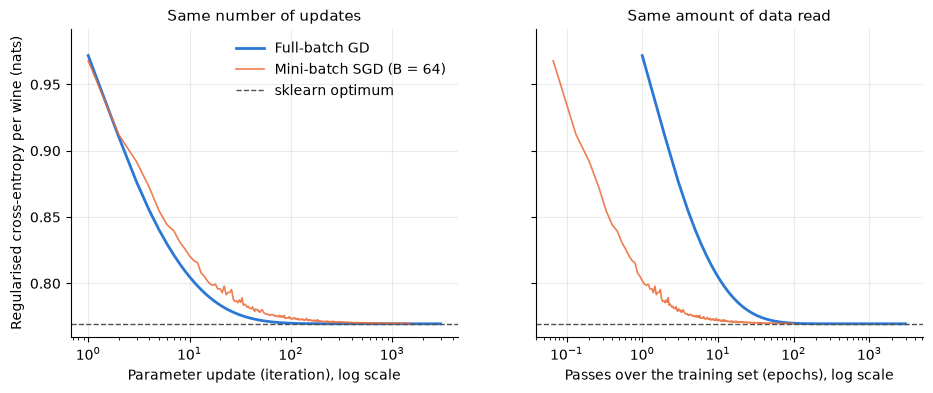

Summary: the analytic gradient matches finite differences (rel. error 2.0e-10). After 3000 GD steps the objective is within 1.0e-12 nats/wine of sklearn's optimum, and validation probabilities differ from sklearn by at most 5.7e-07.
Mini-batch SGD gets within 2.3e-04 of the optimum in 100 passes (1500 noisy updates; mean |p - p_sklearn| = 0.0039); per pass it makes 15 updates to GD's one, which is why it leads in the right-hand panel.


In [7]:
steps_per_epoch = int(np.ceil(n / 64))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, xs_sgd, xlabel in [(axes[0], np.arange(1, len(h_sgd) + 1), "Parameter update (iteration)"),
                           (axes[1], np.arange(1, len(h_sgd) + 1) / steps_per_epoch, "Passes over the training set (epochs)")]:
    ax.plot(np.arange(1, len(h_gd) + 1), h_gd, color=PALETTE[0], lw=2, label="Full-batch GD")
    ax.plot(xs_sgd, h_sgd, color=PALETTE[1], lw=1.2, alpha=0.85, label="Mini-batch SGD (B = 64)")
    ax.axhline(J_sk, color="#52514e", ls="--", lw=1, label="sklearn optimum")
    ax.set_xscale("log"); ax.set_xlabel(xlabel + ", log scale")
axes[0].set_ylabel("Regularised cross-entropy per wine (nats)")
axes[0].set_title("Same number of updates"); axes[1].set_title("Same amount of data read")
axes[0].legend(frameon=False)
axes[0].set_ylim(J_sk - 0.01, max(h_gd[0], h_sgd[0]) + 0.02)
savefig(fig, "lr_step1_loss_curves.png"); plt.show()

gap_gd, gap_sgd = h_gd[-1] - J_sk, h_sgd[-1] - J_sk
print(f"Summary: the analytic gradient matches finite differences (rel. error {rel_err:.1e}). "
      f"After {len(h_gd)} GD steps the objective is within {max(abs(gap_gd), 1e-12):.1e} nats/wine of sklearn's optimum, and "
      f"validation probabilities differ from sklearn by at most {step1.loc[0, 'max_abs_prob_diff_vs_sklearn_val']:.1e}.\n"
      f"Mini-batch SGD gets within {gap_sgd:.1e} of the optimum in {SGD_EPOCHS} passes ({len(h_sgd)} noisy updates; mean "
      f"|p - p_sklearn| = {step1.loc[1, 'mean_abs_prob_diff_vs_sklearn_val']:.4f}); per pass it makes {steps_per_epoch} updates "
      f"to GD's one, which is why it leads in the right-hand panel.")


C sweep: bias vs variance (5 × 5 repeated CV)
`C = 1/λ`. Small C = strong shrinkage (high bias); large C = weak shrinkage (higher variance).
The scaler lives inside the pipeline, so in each fold it is fitted on that fold's training part only.

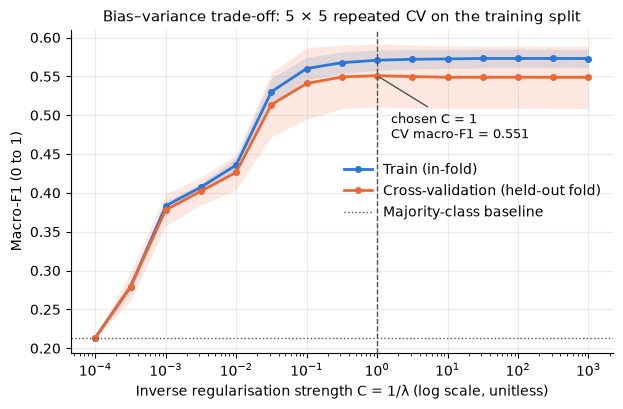

        C  train_mean  cv_mean  cv_std
   0.0001      0.2135   0.2135  0.0007
   0.0003      0.2791   0.2794  0.0186
   0.0010      0.3832   0.3780  0.0204
   0.0032      0.4074   0.4022  0.0178
   0.0100      0.4358   0.4264  0.0225
   0.0316      0.5303   0.5136  0.0415
   0.1000      0.5601   0.5408  0.0461
   0.3162      0.5676   0.5492  0.0412
   1.0000      0.5708   0.5508  0.0403
   3.1623      0.5720   0.5497  0.0407
  10.0000      0.5725   0.5488  0.0402
  31.6228      0.5730   0.5488  0.0402
 100.0000      0.5730   0.5488  0.0402
 316.2278      0.5730   0.5488  0.0402
1000.0000      0.5729   0.5488  0.0402

Summary: CV macro-F1 rises from 0.213 at C=1e-4 (heavy shrinkage, underfitting) to a plateau: for every C >= 0.1 it stays within 0.010, while the fold-to-fold SD is 0.040, so any C on the plateau is about as good; the maximum is at C = 1.
The train-CV gap at the chosen C is 0.020: small, so the linear model is limited by bias rather than variance.


In [8]:
C_GRID = np.logspace(-4, 3, 15)

def lr_pipe(C, **kw):
    """StandardScaler + multinomial L2 logistic regression."""
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=10000, **kw))

rows = []
for C in C_GRID:
    r = cross_validate(lr_pipe(C), X_tr, y_tr, cv=RCV, scoring="f1_macro", return_train_score=True, n_jobs=-1)
    rows.append({"C": C, "train_mean": r["train_score"].mean(), "train_std": r["train_score"].std(),
                 "cv_mean": r["test_score"].mean(), "cv_std": r["test_score"].std()})
sweep = pd.DataFrame(rows)
i_best = int(sweep["cv_mean"].idxmax())
C_best = float(sweep.loc[i_best, "C"])
se_best = sweep.loc[i_best, "cv_std"] / np.sqrt(N_SPLITS)          # SE of the mean; folds within a repeat are independent
C_1se = float(sweep.loc[sweep["cv_mean"] >= sweep.loc[i_best, "cv_mean"] - se_best, "C"].min())
sweep["chosen"] = sweep.index == i_best
save_table(sweep.round(5), "lr_step2_c_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.2))
for col, color, label in [("train", PALETTE[0], "Train (in-fold)"), ("cv", PALETTE[1], "Cross-validation (held-out fold)")]:
    ax.plot(sweep["C"], sweep[f"{col}_mean"], "o-", color=color, lw=2, ms=4, label=label)
    ax.fill_between(sweep["C"], sweep[f"{col}_mean"] - sweep[f"{col}_std"],
                    sweep[f"{col}_mean"] + sweep[f"{col}_std"], color=color, alpha=0.15, lw=0)
ax.axhline(cv_dummy["macro_f1"].mean(), color="#52514e", ls=":", lw=1, label="Majority-class baseline")
ax.axvline(C_best, color="#52514e", ls="--", lw=1)
ax.annotate(f"chosen C = {C_best:.3g}\nCV macro-F1 = {sweep.loc[i_best, 'cv_mean']:.3f}",
            xy=(C_best, sweep.loc[i_best, "cv_mean"]), xytext=(10, -45), textcoords="offset points",
            fontsize=9, arrowprops=dict(arrowstyle="-", color="#52514e"))
ax.set_xscale("log")
ax.set_xlabel("Inverse regularisation strength C = 1/λ (log scale, unitless)")
ax.set_ylabel("Macro-F1 (0 to 1)")
ax.set_title("Bias–variance trade-off: 5 × 5 repeated CV on the training split")
ax.legend(frameon=False, loc="center right")
savefig(fig, "lr_step2_c_sweep.png"); plt.show()

print(sweep[["C", "train_mean", "cv_mean", "cv_std"]].round(4).to_string(index=False))
gap = sweep.loc[i_best, "train_mean"] - sweep.loc[i_best, "cv_mean"]
plateau = sweep.loc[sweep["C"] >= C_1se, "cv_mean"]
print(f"\nSummary: CV macro-F1 rises from {sweep['cv_mean'].iloc[0]:.3f} at C=1e-4 (heavy shrinkage, underfitting) to a "
      f"plateau: for every C >= {C_1se:.3g} it stays within {plateau.max() - plateau.min():.3f}, while the fold-to-fold SD is "
      f"{sweep.loc[i_best, 'cv_std']:.3f}, so any C on the plateau is about as good; the maximum is at C = {C_best:.3g}.\n"
      f"The train-CV gap at the chosen C is {gap:.3f}: "
      f"{'small, so the linear model is limited by bias rather than variance' if gap < 0.03 else 'noticeable, so variance matters on this small dataset'}.")

#L1 vs L2 coefficient paths#
L1 adds $\lambda\sum|w|$: its corner at 0 sets weak coefficients **exactly** to zero as C shrinks (feature selection).
L2 adds $\tfrac{\lambda}{2}\sum w^2$: it shrinks coefficients smoothly but never to exactly zero.

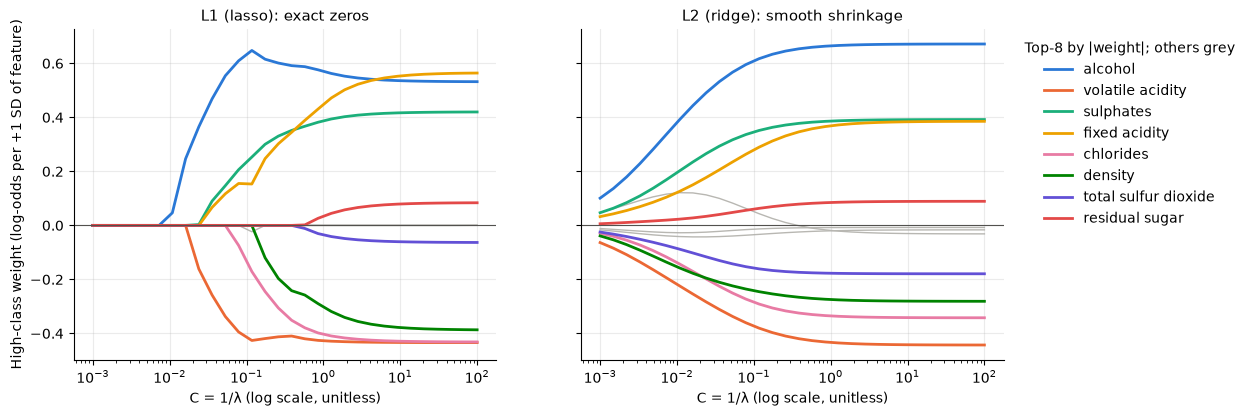

                          feature  C_enters_L1
zeroed_rank                                   
1             free sulfur dioxide      67.2336
2                     citric acid      45.2035
3                  residual sugar       0.5736
4            total sulfur dioxide       0.5736
5                         density       0.1743
6                              pH       0.1172
7                       chlorides       0.0788
8                   fixed acidity       0.0356
9                volatile acidity       0.0240
10                      sulphates       0.0240
11                        alcohol       0.0108

(0 of 60 saga fits hit max_iter.)
Summary: under L1 the first features to drop out of the High-class model as C shrinks are free sulfur dioxide, citric acid, residual sugar; the last to survive are sulphates, alcohol, so those two carry the most High-vs-rest signal per unit of penalty. Under L2 no weight is ever exactly zero (smallest |w| on the path = 1.2e-03).


In [9]:
C_PATH = np.logspace(-3, 2, 30)              # ascending, so warm starts move from sparse to dense
paths, not_converged = {}, 0
for pen in ["l1", "l2"]:
    clf = LogisticRegression(solver="saga", C=C_PATH[0], max_iter=20000, tol=1e-4,
                             warm_start=True, random_state=SEED, **pen_kw(pen))
    coefs = []
    for C in C_PATH:
        clf.set_params(C=C)
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always", ConvergenceWarning)
            clf.fit(Z_tr, y_tr)                              # Z_tr: standardised with the train scaler
        not_converged += sum(issubclass(x.category, ConvergenceWarning) for x in w)
        coefs.append(clf.coef_[2].copy())                    # row 2 = High class
    paths[pen] = pd.DataFrame(coefs, index=C_PATH, columns=FEATURES)
    save_table(paths[pen].round(6), f"lr_step3_path_{pen}_high.csv")

# When does each feature leave the L1 model as C decreases? Find the smallest C at which it is non-zero.
TOL = 1e-8
order_rows = []
for f in FEATURES:
    nz = np.abs(paths["l1"][f].to_numpy()) > TOL
    first_active = int(np.argmax(nz)) if nz.any() else None   # first index (ascending C) where it is active
    order_rows.append({"feature": f,
                       "C_enters_L1": C_PATH[first_active] if first_active is not None else np.nan,
                       "coef_L1_at_C=100": paths["l1"][f].iloc[-1],
                       "coef_L2_at_C=100": paths["l2"][f].iloc[-1],
                       "min_abs_coef_L2_on_path": np.abs(paths["l2"][f]).min()})
zero_order = (pd.DataFrame(order_rows).sort_values("C_enters_L1", ascending=False, na_position="first")
              .reset_index(drop=True))
zero_order.index = zero_order.index + 1                       # rank 1 = first to hit zero
zero_order.index.name = "zeroed_rank"
save_table(zero_order.round(5), "lr_step3_l1_zero_order.csv")

# Colour the 8 features with the largest |L2 weight| at C=100; grey for the rest.
top = paths["l2"].iloc[-1].abs().sort_values(ascending=False).index[:8].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, pen, title in [(axes[0], "l1", "L1 (lasso): exact zeros"), (axes[1], "l2", "L2 (ridge): smooth shrinkage")]:
    for f in FEATURES:
        if f not in top:
            ax.plot(C_PATH, paths[pen][f], color=GREY, lw=1, zorder=1)
    for f, c in zip(top, PALETTE):
        ax.plot(C_PATH, paths[pen][f], color=c, lw=2, label=f, zorder=2)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xscale("log"); ax.set_title(title)
    ax.set_xlabel("C = 1/λ (log scale, unitless)")
axes[0].set_ylabel("High-class weight (log-odds per +1 SD of feature)")
axes[1].legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left", title="Top-8 by |weight|; others grey")
savefig(fig, "lr_step3_l1_vs_l2_paths.png"); plt.show()

print(zero_order[["feature", "C_enters_L1"]].round(4).to_string())
print(f"\n({not_converged} of {2 * len(C_PATH)} saga fits hit max_iter.)")
print(f"Summary: under L1 the first features to drop out of the High-class model as C shrinks are "
      f"{', '.join(zero_order['feature'].head(3))}; the last to survive are {', '.join(zero_order['feature'].tail(2))}, "
      f"so those two carry the most High-vs-rest signal per unit of penalty. Under L2 no weight is ever exactly zero "
      f"(smallest |w| on the path = {zero_order['min_abs_coef_L2_on_path'].min():.1e}).")

Because the features are standardised, each weight is the change in a class score per **+1 SD** of that feature.
In a multinomial model only differences between classes are identified, so the table also gives $w_{High}-w_{Low}$:
the change in $\log\frac{P(High)}{P(Low)}$ per +1 SD.
Permutation importance is computed inside the 25 CV folds (10 shuffles per fold), not on the 204-wine validation set.

In [10]:
best_lr = lr_pipe(C_best).fit(X_tr, y_tr)
W_best = best_lr[-1].coef_                                     # (3, 11), standardised scale
coef_df = pd.DataFrame(W_best.T, index=FEATURES, columns=[f"w_{c}" for c in CLASS_NAMES])
coef_df["High_minus_Low"] = coef_df["w_High"] - coef_df["w_Low"]
coef_df["max_abs_w"] = np.abs(W_best).max(axis=0)
coef_df = coef_df.sort_values("High_minus_Low", key=np.abs, ascending=False)
save_table(coef_df.round(4), "lr_step4_std_coefficients.csv")
print(coef_df.round(3).to_string())

# Linear model at the chosen C, scored on the shared 25 folds; reused in steps 5, 6 and 8.
cv_lin, oof_lin = repeated_cv(lambda: lr_pipe(C_best), X_tr, y_tr, f"LR multinomial (C={C_best:.3g})")

# ---- Correlated inputs: the strongest pairs, and the density / residual sugar pair from the brief ----
corr = X_tr.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs = pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(5).reset_index(drop=True)
save_table(pairs.round(4), "lr_step4_top_correlations.csv", index=False)

r_ds = corr.loc["density", "residual sugar"]
w_d, w_s = coef_df.loc["density", "High_minus_Low"], coef_df.loc["residual sugar", "High_minus_Low"]
rank = coef_df["High_minus_Low"].abs().rank(ascending=False).astype(int)
no_dens = [f for f in FEATURES if f != "density"]
lr_nd = lr_pipe(C_best).fit(X_tr[no_dens], y_tr)              # refit without density
w_nd = pd.Series(lr_nd[-1].coef_[2] - lr_nd[-1].coef_[0], index=no_dens)   # High - Low weights without density
cv_nd, _ = repeated_cv(lambda: lr_pipe(C_best), X_tr[no_dens], y_tr, "LR without density")
p_nd = paired(cv_nd, cv_lin)
moved = (w_nd - coef_df.loc[no_dens, "High_minus_Low"]).abs().sort_values(ascending=False)  # whose weight changes most
collin = pd.DataFrame({"quantity": ["corr(density, residual sugar), train", "density High-Low weight",
                                    "residual sugar High-Low weight", "residual sugar High-Low weight WITHOUT density",
                                    "CV macro-F1 change without density (mean)", "CV macro-F1 change without density (SD)"],
                       "value": [r_ds, w_d, w_s, w_nd["residual sugar"], p_nd["mean_diff"], p_nd["sd_diff"]]})
save_table(collin.round(4), "lr_step4_density_sugar.csv", index=False)
print("\nStrongest correlations between inputs (train):\n" + pairs.round(3).to_string(index=False))
print("\n" + collin.round(3).to_string(index=False))
print(f"density rank {rank['density']}/11, residual sugar rank {rank['residual sugar']}/11 by |High-Low weight|; "
      f"signs {'OPPOSITE' if np.sign(w_d) != np.sign(w_s) else 'SAME'}. "
      f"Weights that move most when density is removed: "
      + ", ".join(f"{f} ({coef_df.loc[f, 'High_minus_Low']:+.2f} -> {w_nd[f]:+.2f})" for f in moved.index[:3]))

                      w_Low  w_Medium  w_High  High_minus_Low  max_abs_w
alcohol              -0.803     0.137   0.666           1.469      0.803
volatile acidity      0.446    -0.011  -0.435          -0.881      0.446
sulphates            -0.359    -0.026   0.385           0.745      0.385
chlorides             0.248     0.087  -0.335          -0.583      0.335
fixed acidity        -0.199    -0.166   0.366           0.565      0.366
total sulfur dioxide  0.292    -0.116  -0.177          -0.469      0.292
density               0.104     0.166  -0.271          -0.375      0.271
pH                    0.099    -0.078  -0.021          -0.120      0.099
citric acid           0.087    -0.068  -0.019          -0.106      0.087
residual sugar        0.007    -0.090   0.084           0.077      0.090
free sulfur dioxide  -0.071     0.080  -0.008           0.063      0.080

Strongest correlations between inputs (train):
          feature_a            feature_b      r
      fixed acidity         

                      abs_High_minus_Low  max_abs_w    VIF  perm_drop_macro_f1_mean  perm_drop_macro_f1_sd_over_folds  folds_with_positive_drop  rank_coef  rank_perm
alcohol                            1.469      0.803  3.060                    0.143                             0.040                        25          1          1
volatile acidity                   0.881      0.446  1.769                    0.059                             0.028                        24          2          2
sulphates                          0.745      0.385  1.471                    0.045                             0.031                        22          3          3
fixed acidity                      0.565      0.366  8.120                    0.030                             0.024                        22          4          4
density                            0.375      0.271  6.330                    0.026                             0.029                        21          7          5
citr

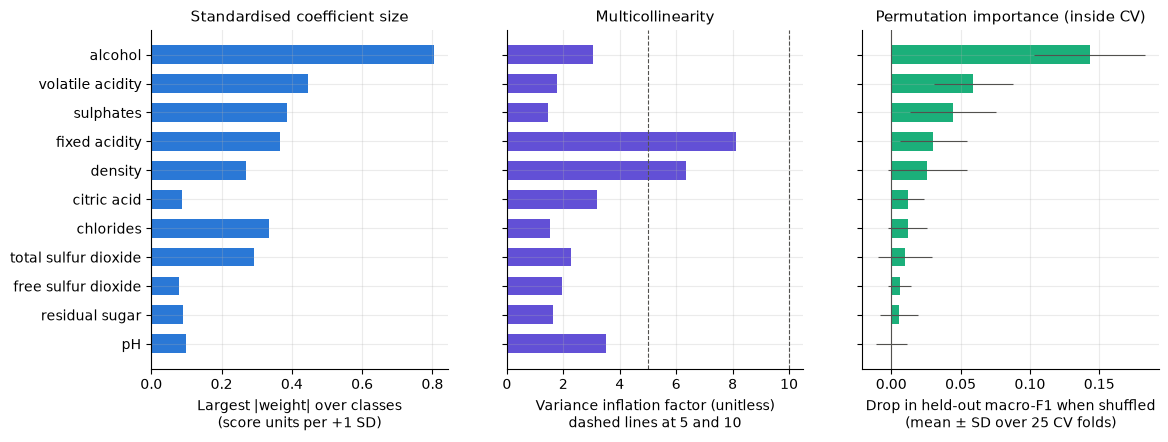

Summary: 2 feature(s) have VIF > 5 (fixed acidity 8.1, density 6.3). Density and residual sugar (r = 0.32) get High-Low weights -0.37 and +0.08 (ranks 7 and 10 of 11), so on red wine they are NOT a large opposite-signed pair.
Removing density mainly shifts fixed acidity (r with density = +0.68) from +0.56 to +0.27, while CV macro-F1 changes by -0.004 (SD 0.012): the two share one signal.
Features whose shuffling hurts in at least 20 of 25 folds: alcohol, volatile acidity, sulphates, fixed acidity, density, citric acid, chlorides, free sulfur dioxide. Rank correlation between weight size and permutation importance is 0.81; ranked 3+ places lower by permutation than by weight: pH (VIF 3.5).


In [11]:
# ---- VIF on the standardised training features (VIF_j = 1 / (1 - R^2_j)) ----
Zc = sm.add_constant(pd.DataFrame(Z_tr, columns=FEATURES))     # VIF assumes an intercept in each auxiliary regression
vif = pd.Series([variance_inflation_factor(Zc.values, i) for i in range(1, Zc.shape[1])], index=FEATURES, name="VIF")

# ---- Permutation importance inside CV: fit on each training fold, shuffle columns of its held-out fold ----
perm = np.zeros((N_SPLITS * N_REPEATS, len(FEATURES)))
for k, (tr, ho) in enumerate(RCV.split(X_tr, y_tr)):
    m = lr_pipe(C_best).fit(X_tr.iloc[tr], y_tr[tr])
    pi = permutation_importance(m, X_tr.iloc[ho], y_tr[ho], scoring="f1_macro", n_repeats=10,
                                random_state=SEED + k)            # different shuffles per fold, still reproducible
    perm[k] = pi.importances_mean                                # mean drop over 10 shuffles in this fold

imp = pd.DataFrame({"abs_High_minus_Low": coef_df["High_minus_Low"].abs(), "max_abs_w": coef_df["max_abs_w"],
                    "VIF": vif,
                    "perm_drop_macro_f1_mean": pd.Series(perm.mean(axis=0), index=FEATURES),
                    "perm_drop_macro_f1_sd_over_folds": pd.Series(perm.std(axis=0, ddof=1), index=FEATURES),
                    "folds_with_positive_drop": pd.Series((perm > 0).sum(axis=0), index=FEATURES)})
imp["rank_coef"] = imp["max_abs_w"].rank(ascending=False).astype(int)
imp["rank_perm"] = imp["perm_drop_macro_f1_mean"].rank(ascending=False).astype(int)
imp = imp.sort_values("perm_drop_macro_f1_mean", ascending=False)
save_table(imp.round(5), "lr_step4_vif_permutation.csv")
print(imp.round(3).to_string())

order = imp.index[::-1]                                        # largest at the top of a barh chart
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
axes[0].barh(order, imp.loc[order, "max_abs_w"], color=PALETTE[0], height=0.65)
axes[0].set_xlabel("Largest |weight| over classes\n(score units per +1 SD)")
axes[0].set_title("Standardised coefficient size")
axes[1].barh(order, imp.loc[order, "VIF"], color=PALETTE[6], height=0.65)
for v in (5, 10):
    axes[1].axvline(v, color="#52514e", ls="--", lw=0.8)
axes[1].set_xlabel("Variance inflation factor (unitless)\ndashed lines at 5 and 10")
axes[1].set_title("Multicollinearity")
axes[2].barh(order, imp.loc[order, "perm_drop_macro_f1_mean"], xerr=imp.loc[order, "perm_drop_macro_f1_sd_over_folds"],
             color=PALETTE[2], height=0.65, error_kw=dict(lw=0.8, ecolor="#52514e"))
axes[2].axvline(0, color="#52514e", lw=0.8)
axes[2].set_xlabel("Drop in held-out macro-F1 when shuffled\n(mean ± SD over 25 CV folds)")
axes[2].set_title("Permutation importance (inside CV)")
savefig(fig, "lr_step4_coef_vif_permutation.png"); plt.show()

big_vif = vif[vif > 5].sort_values(ascending=False)
rho = imp["rank_coef"].corr(imp["rank_perm"], method="spearman")
demoted = imp.index[imp["rank_perm"] - imp["rank_coef"] >= 3].tolist()   # big weight, small permutation effect
demoted_txt = ", ".join(f"{f} (VIF {imp.loc[f, 'VIF']:.1f})" for f in demoted) or "none"
clear = imp.index[imp["folds_with_positive_drop"] >= 20].tolist()        # helps in at least 20 of 25 folds
big_pair = (np.sign(w_d) != np.sign(w_s)) and max(rank["density"], rank["residual sugar"]) <= 4
m0 = moved.index[0]
print(f"Summary: {len(big_vif)} feature(s) have VIF > 5 ({', '.join(f'{k} {v:.1f}' for k, v in big_vif.items()) or 'none'}). "
      f"Density and residual sugar (r = {r_ds:.2f}) get High-Low weights {w_d:+.2f} and {w_s:+.2f} (ranks {rank['density']} and "
      f"{rank['residual sugar']} of 11), so {'they ARE' if big_pair else 'on red wine they are NOT'} a large opposite-signed pair.\n"
      f"Removing density mainly shifts {m0} (r with density = {corr.loc[m0, 'density']:+.2f}) from "
      f"{coef_df.loc[m0, 'High_minus_Low']:+.2f} to {w_nd[m0]:+.2f}, while CV macro-F1 changes by {p_nd['mean_diff']:+.3f} "
      f"(SD {p_nd['sd_diff']:.3f}): the two share one signal.\n"
      f"Features whose shuffling hurts in at least 20 of 25 folds: {', '.join(clear) or 'none'}. Rank correlation between "
      f"weight size and permutation importance is {rho:.2f}; ranked 3+ places lower by permutation than by weight: {demoted_txt}.")

 logit vs multinomial

Ordinal model: one weight vector $w$ and two cut-points $\theta_1<\theta_2$:
$P(y\le j\mid x)=\sigma(\theta_j - w\cdot x)$, so $P(Low)=\sigma(\theta_1-w\cdot x)$, $P(Med)=\sigma(\theta_2-w\cdot x)-\sigma(\theta_1-w\cdot x)$, $P(High)=1-\sigma(\theta_2-w\cdot x)$.
It uses 11 + 2 = 13 parameters instead of 3 × 12 = 36. statsmodels fits it by unregularised maximum likelihood (no C).
Both models are scored on the same 25 folds.

In [12]:
ord_pipe = lambda: make_pipeline(StandardScaler(), OrdinalLogit())
cv_ord, oof_ord = repeated_cv(ord_pipe, X_tr, y_tr, "LR ordinal logit")
ord_fit = ord_pipe().fit(X_tr, y_tr)                              # full-training-split fit, for weights and later use
res = ord_fit[-1].res_
thresholds = res.model.transform_threshold_params(res.params)[1:-1]   # drop the -inf / +inf ends
ord_w = pd.Series(np.asarray(res.params)[:len(FEATURES)], index=FEATURES, name="ordinal_w")

cmp5 = pd.concat({"multinomial": cv_summary(cv_lin), "ordinal": cv_summary(cv_ord)}, axis=1)
save_table(cmp5.round(4), "lr_step5_ordinal_vs_multinomial_cv.csv")
save_table(pd.concat([ord_w, coef_df["High_minus_Low"]], axis=1).round(4), "lr_step5_ordinal_weights.csv")
p_qwk, p_f1 = paired(cv_ord, cv_lin, "qwk"), paired(cv_ord, cv_lin, "macro_f1")
far = lambda oof: np.mean([np.mean(np.abs(oof[r].argmax(1) - y_tr) == 2) for r in range(N_REPEATS)])   # Low <-> High misses
far_mn, far_ord = far(oof_lin), far(oof_ord)
print(cmp5.round(3).to_string())
print(f"cut-points theta_1 = {thresholds[0]:.3f}, theta_2 = {thresholds[1]:.3f}")
print(f"Ordinal minus multinomial over 25 paired folds: QWK {p_qwk['mean_diff']:+.3f} (SD {p_qwk['sd_diff']:.3f}, "
      f"ordinal better in {p_qwk['folds_a_better']}/25), macro-F1 {p_f1['mean_diff']:+.3f} (SD {p_f1['sd_diff']:.3f}, "
      f"better in {p_f1['folds_a_better']}/25).")
verdict = ("no reliable difference" if abs(p_qwk["mean_diff"]) < p_qwk["sd_diff"] else
           "the ordinal model is better on QWK" if p_qwk["mean_diff"] > 0 else "the multinomial model is better on QWK")
print(f"Summary: with 13 instead of 36 parameters, {verdict} (the mean QWK difference is "
      f"{'smaller' if abs(p_qwk['mean_diff']) < p_qwk['sd_diff'] else 'larger'} than its fold-to-fold SD). "
      f"Far misses (Low <-> High), which QWK punishes most, are {far_mn:.1%} of multinomial and {far_ord:.1%} of "
      f"ordinal out-of-fold predictions.")

                  multinomial        ordinal       
                         mean    std    mean    std
accuracy                0.617  0.029   0.626  0.037
balanced_accuracy       0.540  0.040   0.551  0.046
macro_f1                0.551  0.041   0.565  0.049
qwk                     0.530  0.047   0.543  0.056
log_loss                0.800  0.042   0.792  0.042
recall_Low              0.770  0.039   0.759  0.046
recall_Medium           0.538  0.048   0.570  0.065
recall_High             0.313  0.091   0.322  0.096
cut-points theta_1 = -0.253, theta_2 = 2.573
Ordinal minus multinomial over 25 paired folds: QWK +0.013 (SD 0.025, ordinal better in 17/25), macro-F1 +0.014 (SD 0.026, better in 19/25).
Summary: with 13 instead of 36 parameters, no reliable difference (the mean QWK difference is smaller than its fold-to-fold SD). Far misses (Low <-> High), which QWK punishes most, are 1.5% of multinomial and 1.2% of ordinal out-of-fold predictions.


Adds all squares and pairwise products (11 → 77 features). The model is still linear in its parameters, so training stays convex,
but the decision boundary in the original features is now quadratic. C is re-tuned with the same 5 × 5 CV.
Set `FFNN_RED_CV_MACRO_F1` in the first code cell to compare with the FFNN pair's red-only result.

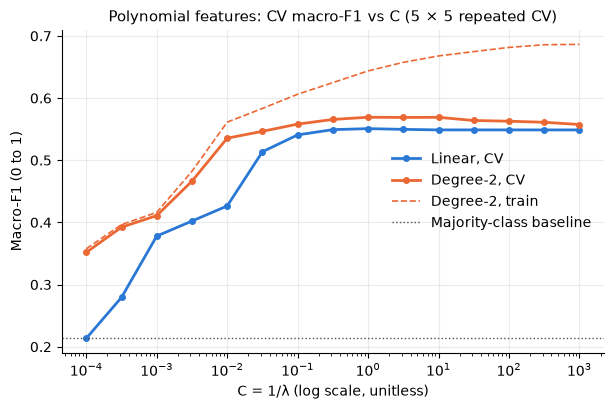

                  linear         poly2       
                    mean    std   mean    std
accuracy           0.617  0.029  0.621  0.028
balanced_accuracy  0.540  0.040  0.558  0.034
macro_f1           0.551  0.041  0.569  0.035
qwk                0.530  0.047  0.531  0.050
log_loss           0.800  0.042  0.825  0.073
recall_Low         0.770  0.039  0.747  0.050
recall_Medium      0.538  0.048  0.557  0.045
recall_High        0.313  0.091  0.370  0.097
Poly-2 minus linear over 25 paired folds: macro-F1 +0.018 (SD 0.031), poly better in 20/25.
Summary: degree-2 features change 5 × 5 CV macro-F1 from 0.551 ± 0.041 to 0.569 ± 0.035 (chosen C = 1); the train-CV gap at that C is 0.075, against 0.020 for the linear model, so the extra features add variance.
On the other metrics poly-2 changes QWK by +0.001 and log loss by +0.025 (positive = worse for log loss). FFNN comparison skipped: set FFNN_RED_CV_MACRO_F1 in the first code cell.


In [13]:
def poly_pipe(C):
    return make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(),
                         LogisticRegression(C=C, max_iter=20000))

rows = []
for C in C_GRID:
    r = cross_validate(poly_pipe(C), X_tr, y_tr, cv=RCV, scoring="f1_macro", return_train_score=True, n_jobs=-1)
    rows.append({"C": C, "train_mean": r["train_score"].mean(), "cv_mean": r["test_score"].mean(), "cv_std": r["test_score"].std()})
sweep_poly = pd.DataFrame(rows)
C_poly = float(sweep_poly.loc[sweep_poly["cv_mean"].idxmax(), "C"])
save_table(sweep_poly.round(5), "lr_step6_poly_c_sweep.csv", index=False)

cv_poly, oof_poly = repeated_cv(lambda: poly_pipe(C_poly), X_tr, y_tr, f"LR poly-2 (C={C_poly:.3g})")
poly_lr = poly_pipe(C_poly).fit(X_tr, y_tr)
p_poly = paired(cv_poly, cv_lin)
cmp6 = pd.concat({"linear": cv_summary(cv_lin), "poly2": cv_summary(cv_poly)}, axis=1)
save_table(cmp6.round(4), "lr_step6_poly_vs_linear_cv.csv")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(sweep["C"], sweep["cv_mean"], "o-", color=PALETTE[0], lw=2, ms=4, label="Linear, CV")
ax.plot(sweep_poly["C"], sweep_poly["cv_mean"], "o-", color=PALETTE[1], lw=2, ms=4, label="Degree-2, CV")
ax.plot(sweep_poly["C"], sweep_poly["train_mean"], "--", color=PALETTE[1], lw=1.2, label="Degree-2, train")
if FFNN_RED_CV_MACRO_F1 is not None:
    ax.axhline(FFNN_RED_CV_MACRO_F1, color=PALETTE[2], ls=":", lw=1.5, label=f"FFNN, red only ({FFNN_RED_CV_MACRO_F1:.3f})")
ax.axhline(cv_dummy["macro_f1"].mean(), color="#52514e", ls=":", lw=1, label="Majority-class baseline")
ax.set_xscale("log"); ax.set_xlabel("C = 1/λ (log scale, unitless)"); ax.set_ylabel("Macro-F1 (0 to 1)")
ax.set_title("Polynomial features: CV macro-F1 vs C (5 × 5 repeated CV)")
ax.legend(frameon=False, loc="center right")
savefig(fig, "lr_step6_poly_c_sweep.png"); plt.show()

print(cmp6.round(3).to_string())
print(f"Poly-2 minus linear over 25 paired folds: macro-F1 {p_poly['mean_diff']:+.3f} (SD {p_poly['sd_diff']:.3f}), "
      f"poly better in {p_poly['folds_a_better']}/25.")
if FFNN_RED_CV_MACRO_F1 is not None and FFNN_RED_CV_MACRO_F1 > cv_lin["macro_f1"].mean():
    recovered = p_poly["mean_diff"] / (FFNN_RED_CV_MACRO_F1 - cv_lin["macro_f1"].mean())
    ffnn_txt = f"That is {recovered:.0%} of the gap between linear LR and the FFNN's red-only {FFNN_RED_CV_MACRO_F1:.3f}."
else:
    recovered = np.nan
    ffnn_txt = ("FFNN comparison skipped: set FFNN_RED_CV_MACRO_F1 in the first code cell." if FFNN_RED_CV_MACRO_F1 is None
                else "The FFNN's red-only score is not above linear LR, so there is no gap to recover.")
print(f"Summary: degree-2 features change 5 × 5 CV macro-F1 from {mean_sd(cv_lin, 'macro_f1')} to "
      f"{mean_sd(cv_poly, 'macro_f1')} (chosen C = {C_poly:.3g}); the train-CV gap at that C is "
      f"{sweep_poly.loc[sweep_poly['C'] == C_poly, 'train_mean'].iloc[0] - sweep_poly['cv_mean'].max():.3f}, against "
      f"{gap:.3f} for the linear model, so the extra features add variance.\nOn the other metrics poly-2 changes QWK by "
      f"{paired(cv_poly, cv_lin, 'qwk')['mean_diff']:+.3f} and log loss by {paired(cv_poly, cv_lin, 'log_loss')['mean_diff']:+.3f} "
      f"(positive = worse for log loss). {ffnn_txt}")

Labels $y\in\{-1,+1\}$ (+1 = High). Score $f(x)=w\cdot x+b$, **margin** $z = y\,f(x)$: positive means correctly classified, and larger means more confidently so.
Zero-one loss $\mathbb 1[z\le 0]$; hinge loss $\max(0, 1-z)$; logistic loss $\log(1+e^{-z})$. LR minimises the logistic loss.
The margins here are **out-of-fold** on the 951 training wines (5-fold CV), so every wine gets a score from a model that did not see it;
step 8 redraws the histogram on test.

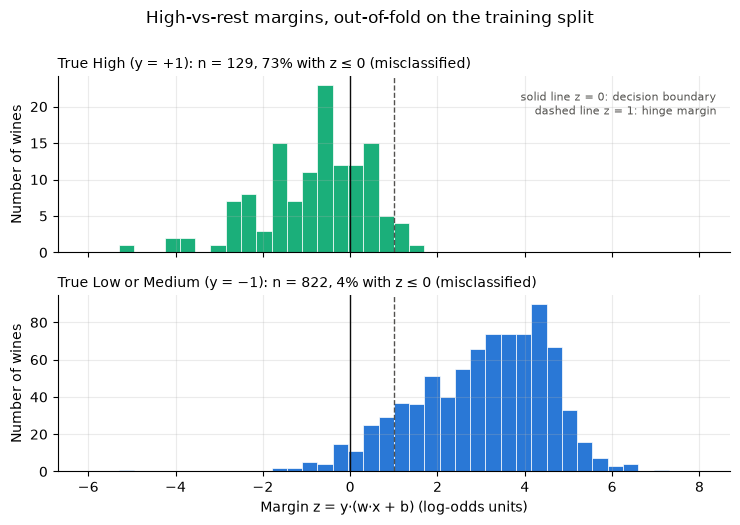

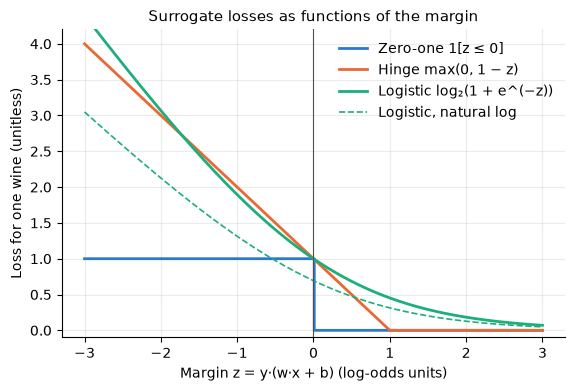

share_misclassified_z<=0         0.131
share_inside_margin_0<z<1        0.098
share_misclassified_true_High    0.729
share_misclassified_true_rest    0.038
mean_zero_one                    0.131
mean_hinge                       0.332
mean_logistic_nats               0.295
Summary: 13.1% of training wines have a non-positive out-of-fold margin (zero-one loss 1) and another 9.8% are correct but inside the hinge margin. The errors are lopsided: 73% of true High wines have z <= 0, against 4% of the rest, because High is only 14% of the data and the threshold sits at p = 0.5.
Logistic loss is a smooth, convex upper bound (in log₂) on zero-one loss, which is why gradient descent can minimise it; zero-one loss has zero gradient almost everywhere.


In [14]:
yb_tr = np.where(y_tr == 2, 1, -1)
bin_lr = lr_pipe(C_best).fit(X_tr, yb_tr)                # classes_ = [-1, +1]; decision_function gives w.x + b for +1
cv5 = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
f_oof = cross_val_predict(lr_pipe(C_best), X_tr, yb_tr, cv=cv5, method="decision_function")
z_oof = yb_tr * f_oof

def plot_margin_hist(zm, ypm, title, fname):
    """Histogram of margins z = y (w.x + b): one panel per true class, shared x-axis."""
    fig, axes = plt.subplots(2, 1, figsize=(7.5, 5.2), sharex=True)
    edges = np.linspace(np.floor(zm.min()), np.ceil(zm.max()), 41)
    for ax, lab, c, name in [(axes[0], 1, CLASS_COLORS["High"], "True High (y = +1)"),
                             (axes[1], -1, PALETTE[0], "True Low or Medium (y = −1)")]:
        zc = zm[ypm == lab]
        ax.hist(zc, bins=edges, color=c, edgecolor="white", linewidth=0.5)
        ax.axvline(0, color="#0b0b0b", lw=1); ax.axvline(1, color="#52514e", lw=1, ls="--")
        ax.set_ylabel("Number of wines")
        ax.set_title(f"{name}: n = {len(zc)}, {np.mean(zc <= 0):.0%} with z ≤ 0 (misclassified)", loc="left", fontsize=10)
    axes[0].text(0.98, 0.92, "solid line z = 0: decision boundary\ndashed line z = 1: hinge margin",
                 transform=axes[0].transAxes, fontsize=8, va="top", ha="right", color="#52514e")
    axes[1].set_xlabel("Margin z = y·(w·x + b) (log-odds units)")
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    savefig(fig, fname); plt.show()

def margin_stats(zm, ypm):
    return {"share_misclassified_z<=0": np.mean(zm <= 0), "share_inside_margin_0<z<1": np.mean((zm > 0) & (zm < 1)),
            "share_misclassified_true_High": np.mean(zm[ypm == 1] <= 0),   # missed High wines
            "share_misclassified_true_rest": np.mean(zm[ypm == -1] <= 0),  # false alarms
            "mean_zero_one": np.mean(zm <= 0), "mean_hinge": np.mean(np.maximum(0, 1 - zm)),
            "mean_logistic_nats": np.mean(np.logaddexp(0, -zm))}           # logaddexp(0,-z) = log(1+e^-z), overflow-safe

plot_margin_hist(z_oof, yb_tr, "High-vs-rest margins, out-of-fold on the training split", "lr_step7_margin_hist_oof_train.png")

zz = np.linspace(-3, 3, 601)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(zz, (zz <= 0).astype(float), color=PALETTE[0], lw=2, drawstyle="steps-post", label="Zero-one 1[z ≤ 0]")
ax.plot(zz, np.maximum(0, 1 - zz), color=PALETTE[1], lw=2, label="Hinge max(0, 1 − z)")
ax.plot(zz, np.logaddexp(0, -zz) / np.log(2), color=PALETTE[2], lw=2, label="Logistic log₂(1 + e^(−z))")
ax.plot(zz, np.logaddexp(0, -zz), color=PALETTE[2], lw=1.2, ls="--", label="Logistic, natural log")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("Margin z = y·(w·x + b) (log-odds units)"); ax.set_ylabel("Loss for one wine (unitless)")
ax.set_ylim(-0.1, 4.2); ax.set_title("Surrogate losses as functions of the margin")
ax.legend(frameon=False)
savefig(fig, "lr_step7_losses_vs_margin.png"); plt.show()

ms_oof = pd.Series(margin_stats(z_oof, yb_tr), name="oof_train")
save_table(ms_oof.round(4).to_frame(), "lr_step7_margin_stats_oof_train.csv")
print(ms_oof.round(3).to_string())
print(f"Summary: {ms_oof['share_misclassified_z<=0']:.1%} of training wines have a non-positive out-of-fold margin "
      f"(zero-one loss 1) and another {ms_oof['share_inside_margin_0<z<1']:.1%} are correct but inside the hinge margin. "
      f"The errors are lopsided: {ms_oof['share_misclassified_true_High']:.0%} of true High wines have z <= 0, against "
      f"{ms_oof['share_misclassified_true_rest']:.0%} of the rest, because High is only {np.mean(yb_tr == 1):.0%} of the data "
      f"and the threshold sits at p = 0.5.\nLogistic loss is a smooth, convex upper bound (in log₂) on zero-one loss, which is "
      f"why gradient descent can minimise it; zero-one loss has zero gradient almost everywhere.")

All three LR variants were scored on the same 25 folds of the training split. With `SELECTION_RULE = "one_se"` (default) the final model is the
**simplest** variant whose CV macro-F1 is within one standard error of the best, where SE = SD of the paired fold differences / √5
(5 independent folds per repeat). Simplest means fewest parameters: ordinal (13) < multinomial (36) < poly-2 (234).
The chosen model is fitted on the training split only, as the data contract requires. Validation scores are printed as a secondary check.

                         n_params  accuracy_mean  balanced_accuracy_mean  macro_f1_mean  qwk_mean  log_loss_mean  macro_f1_std
LR ordinal logit             13.0          0.626                   0.551          0.565     0.543          0.792         0.049
LR multinomial L2 (C=1)      36.0          0.617                   0.540          0.551     0.530          0.800         0.041
LR poly-2 L2 (C=1)          234.0          0.621                   0.558          0.569     0.531          0.825         0.035
Majority class                NaN          0.471                   0.333          0.213     0.000          0.993         0.001

                         n_params  cv_macro_f1_mean  best_minus_this  se_of_diff  within_one_se  best_wins_folds
model                                                                                                           
LR ordinal logit               13             0.565            0.004       0.018           True             14.0
LR multinomial L2 (C=1)  

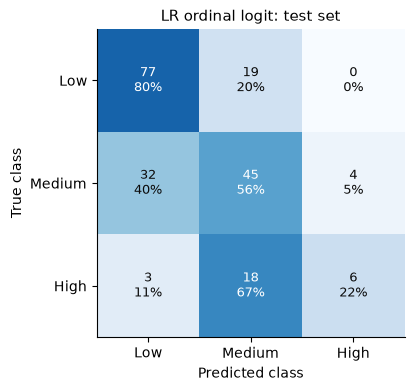


Recall per class:
        n_test  recall_test  recall_cv_mean  recall_cv_sd  recall_majority_baseline
Low         96        0.802           0.759         0.046                       1.0
Medium      81        0.556           0.570         0.065                       0.0
High        27        0.222           0.322         0.096                       0.0


In [15]:
# Listed from simplest to most complex (number of fitted parameters).
candidates = {"LR ordinal logit": (ord_fit, cv_ord, oof_ord),
              f"LR multinomial L2 (C={C_best:.3g})": (best_lr, cv_lin, oof_lin),
              f"LR poly-2 L2 (C={C_poly:.3g})": (poly_lr, cv_poly, oof_poly)}
n_params = {"LR ordinal logit": len(FEATURES) + 2, f"LR multinomial L2 (C={C_best:.3g})": 3 * (len(FEATURES) + 1),
            f"LR poly-2 L2 (C={C_poly:.3g})": 3 * (poly_lr[0].n_output_features_ + 1)}
cv_table = pd.DataFrame({k: {f"{m}_{s}": getattr(v[1][m], s)() for m in METRICS for s in ("mean", "std")}
                         for k, v in candidates.items()}).T
cv_table.loc["Majority class"] = {f"{m}_{s}": getattr(cv_dummy[m], s)() for m in METRICS for s in ("mean", "std")}
top_name = max(candidates, key=lambda k: candidates[k][1]["macro_f1"].mean())   # highest CV mean
sel_rows = []
for k, v in candidates.items():
    p = paired(candidates[top_name][1], v[1])                     # best minus this model, fold by fold
    se = p["sd_diff"] / np.sqrt(N_SPLITS) if k != top_name else 0.0
    sel_rows.append({"model": k, "n_params": n_params[k], "cv_macro_f1_mean": v[1]["macro_f1"].mean(),
                     "best_minus_this": p["mean_diff"], "se_of_diff": se,
                     "within_one_se": p["mean_diff"] <= se, "best_wins_folds": p["folds_a_better"] if k != top_name else np.nan})
selection = pd.DataFrame(sel_rows).set_index("model")
if SELECTION_RULE == "one_se":
    best_name = selection.index[selection["within_one_se"]][0]     # first = simplest, because candidates are ordered
else:
    best_name = top_name
cv_table["n_params"] = pd.Series(n_params)
save_table(cv_table.round(4), "lr_step8_model_choice_cv.csv")
save_table(selection.round(4), "lr_step8_selection_rule.csv")
final_model, cv_final, oof_final = candidates[best_name]
print(cv_table[["n_params"] + [f"{m}_mean" for m in METRICS] + ["macro_f1_std"]].round(3).to_string())
print("\n" + selection.round(3).to_string())
print(f"\nHighest CV macro-F1: {top_name}. Rule '{SELECTION_RULE}' selects: {best_name}")
val_check = pd.DataFrame([evaluate(k, y_va, v[0].predict_proba(X_va)) for k, v in candidates.items()]).set_index("model")
save_table(val_check.round(4), "lr_step8_validation_check.csv")
print("\nValidation check (204 wines, secondary):\n" + val_check.round(3).to_string())

# ---------- FIRST AND ONLY USE OF THE TEST ROWS ----------
X_te = X_all.iloc[idx_te].reset_index(drop=True)
y_te, q_te = y_all[idx_te], q_all[idx_te]
P_te = final_model.predict_proba(X_te)
dummy = make_dummy().fit(X_tr, y_tr)
test_res = pd.DataFrame([evaluate(best_name, y_te, P_te),
                         evaluate("Majority class", y_te, dummy.predict_proba(X_te))]).set_index("model")
save_table(test_res.round(4), "lr_step8_test_metrics.csv")
print("\nTEST metrics:\n" + test_res.round(3).to_string())
cm = plot_confusion(f"{best_name}: test set", y_te, P_te, "lr_step8_confusion_test.png")
save_table(pd.DataFrame(cm, index=[f"true_{c}" for c in CLASS_NAMES], columns=[f"pred_{c}" for c in CLASS_NAMES]),
           "lr_step8_confusion_test.csv")

# ---- Recall per class: test value (small n) next to the CV mean ± SD of the same model ----
recall_tab = pd.DataFrame({"n_test": np.bincount(y_te, minlength=3),
                           "recall_test": class_recall(y_te, P_te.argmax(axis=1)),
                           "recall_cv_mean": cv_final[RECALLS].mean().to_numpy(),
                           "recall_cv_sd": cv_final[RECALLS].std().to_numpy(),
                           "recall_majority_baseline": class_recall(y_te, dummy.predict(X_te))}, index=CLASS_NAMES)
save_table(recall_tab.round(4), "lr_step8_recall_per_class.csv")
print("\nRecall per class:\n" + recall_tab.round(3).to_string())

        class  n_train  error_cv_mean  error_cv_sd_over_repeats  n_test  error_test
grade                                                                              
3         Low        5          0.000                     0.000       3       0.000
4         Low       35          0.291                     0.024      12       0.333
5         Low      408          0.239                     0.003      81       0.185
6      Medium      374          0.430                     0.011      81       0.444
7        High      117          0.713                     0.008      26       0.769
8        High       12          0.333                     0.059       1       1.000


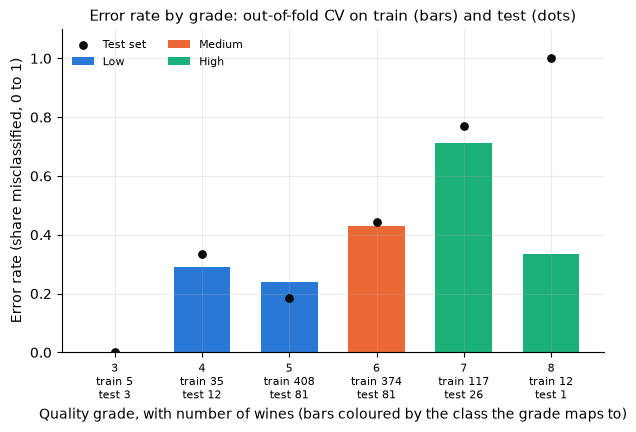

In [16]:
# ---- Error rate by quality grade: out-of-fold on train (main, pooled over 5 repeats) and on test ----
g_rep = [error_by_grade(q_tr, y_tr, oof_final[r].argmax(axis=1))["error_rate"] for r in range(N_REPEATS)]
by_grade = pd.DataFrame({"class": [GRADE_CLASS[g] for g in GRADES],
                         "n_train": pd.Series(q_tr).value_counts().reindex(GRADES, fill_value=0).to_numpy(),
                         "error_cv_mean": pd.concat(g_rep, axis=1).mean(axis=1).to_numpy(),
                         "error_cv_sd_over_repeats": pd.concat(g_rep, axis=1).std(axis=1).to_numpy()}, index=GRADES)
t = error_by_grade(q_te, y_te, P_te.argmax(axis=1))
by_grade["n_test"], by_grade["error_test"] = t["n"].fillna(0).astype(int).to_numpy(), t["error_rate"].to_numpy()
by_grade.index.name = "grade"
save_table(by_grade.round(4), "lr_step8_error_by_grade.csv")
print(by_grade.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4.2))
xg = np.arange(len(GRADES))
for i, g in enumerate(GRADES):
    ax.bar(i, by_grade.loc[g, "error_cv_mean"], width=0.65, color=CLASS_COLORS[GRADE_CLASS[g]],
           label=GRADE_CLASS[g] if GRADE_CLASS[g] not in ax.get_legend_handles_labels()[1] else None)
ok = by_grade["n_test"] > 0
ax.scatter(xg[ok], by_grade.loc[ok, "error_test"], color="#0b0b0b", zorder=3, s=28, label="Test set")
ax.set_xticks(xg, [f"{g}\ntrain {by_grade.loc[g, 'n_train']}\ntest {by_grade.loc[g, 'n_test']}" for g in GRADES], fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_xlabel("Quality grade, with number of wines (bars coloured by the class the grade maps to)")
ax.set_ylabel("Error rate (share misclassified, 0 to 1)")
ax.set_title("Error rate by grade: out-of-fold CV on train (bars) and test (dots)")
ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=8)
savefig(fig, "lr_step8_error_by_grade.png"); plt.show()

                               test  cv_oof_train_pooled
n                           204.000             4755.000
n_marginal                   63.000             1362.000
share_marginal                0.309                0.286
acc_marginal                  0.508                0.540
acc_confident                 0.681                0.660
share_marginal_true_medium    0.476                0.485
share_marginal_pred_medium    0.587                0.529

          test                 cv_oof_train_pooled                
             n accuracy  share                   n accuracy  share
bin                                                               
[0,0.1)     32    0.500  0.157                 635    0.531  0.134
[0.1,0.2)   31    0.516  0.152                 727    0.547  0.153
[0.2,0.4)   69    0.551  0.338                1758    0.575  0.370
[0.4,0.6)   38    0.842  0.186                 856    0.688  0.180
[0.6,1]     34    0.765  0.167                 779    0.823  0.164


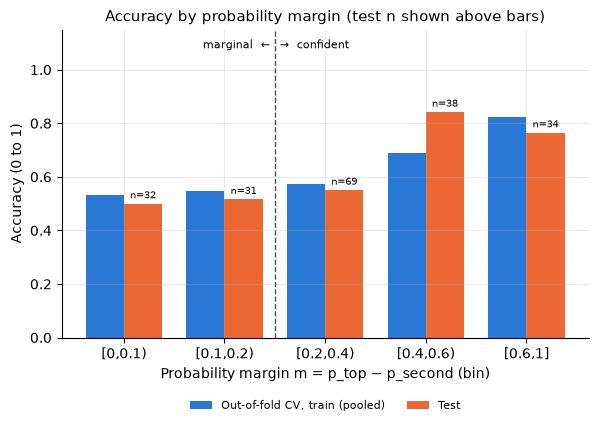


                      mean_marginal_raw  mean_confident_raw  diff_in_train_SD
total sulfur dioxide             30.365              53.617            -0.679
volatile acidity                  0.475               0.574            -0.547
free sulfur dioxide              12.952              18.316            -0.523
alcohol                          10.740              10.202             0.491
pH                                3.282               3.330            -0.303
fixed acidity                     8.465               7.991             0.263
sulphates                         0.690               0.647             0.251
citric acid                       0.280               0.237             0.214
density                           0.996               0.997            -0.154
residual sugar                    2.667               2.495             0.128
chlorides                         0.092               0.086             0.119


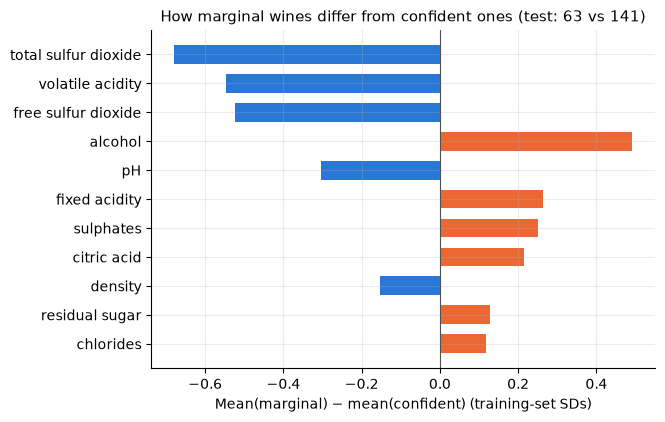

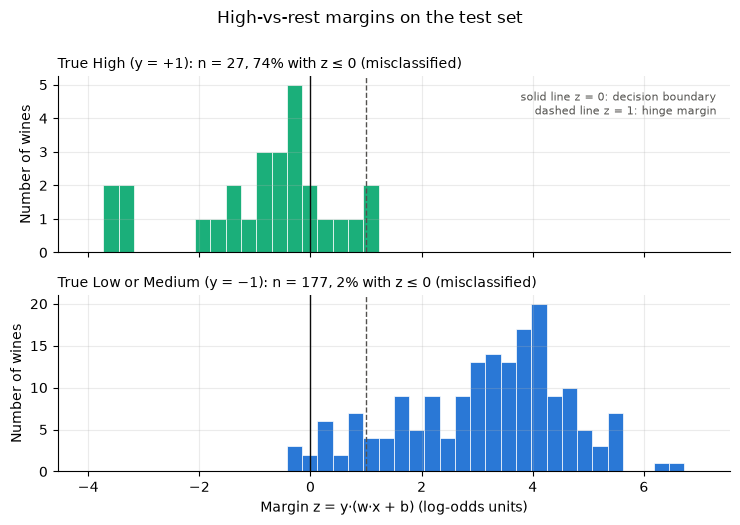


Summary: on test the selected model reaches macro-F1 0.539 vs 0.213 for the majority baseline (CV: 0.565 ± 0.049). High recall is 22% on 27 test wines; the CV estimate is 32% ± 10%.
Out-of-fold error rate by grade (grades with at least 20 training wines): grade 4 29%, grade 5 24%, grade 6 43%, grade 7 71%; the hardest is grade 7.
31% of test wines are marginal (m < 0.2), with accuracy 51% vs 68% for confident wines (CV pooled: 54% vs 66%); marginal wines have total sulfur dioxide lower by 0.68 SD; volatile acidity lower by 0.55 SD; free sulfur dioxide lower by 0.52 SD.
Total runtime: 2.3 min


In [ ]:
# ---- Marginal-case analysis on test (and out-of-fold on train, pooled over the 5 repeats, for stability) ----
mr, mbins = marginal_report(y_te, P_te)
mr_cv, mbins_cv = marginal_report(np.tile(y_tr, N_REPEATS), oof_final.reshape(-1, 3))
marg_tab = pd.DataFrame({"test": mr, "cv_oof_train_pooled": mr_cv})
bins_tab = pd.concat({"test": mbins, "cv_oof_train_pooled": mbins_cv}, axis=1)
save_table(marg_tab.round(4), "lr_step8_marginal_summary.csv")
save_table(bins_tab.round(4), "lr_step8_marginal_bins.csv")
print(marg_tab.round(3).to_string()); print("\n" + bins_tab.round(3).to_string())

fig, ax = plt.subplots(figsize=(6.8, 4))
xb = np.arange(len(MARGIN_LABELS)); w = 0.38
ax.bar(xb - w / 2, mbins_cv["accuracy"], width=w, color=PALETTE[0], label="Out-of-fold CV, train (pooled)")
ax.bar(xb + w / 2, mbins["accuracy"], width=w, color=PALETTE[1], label="Test")
for i in range(len(xb)):
    a = mbins["accuracy"].iloc[i]
    ax.text(i + w / 2, (a if np.isfinite(a) else 0) + 0.02, f"n={mbins['n'].iloc[i]}", ha="center", fontsize=7)
ax.axvline(1.5, color="#52514e", ls="--", lw=1)
ax.text(1.45, 1.08, "marginal  ←", ha="right", fontsize=8); ax.text(1.55, 1.08, "→  confident", fontsize=8)
ax.set_xticks(xb, MARGIN_LABELS); ax.set_ylim(0, 1.15)
ax.set_xlabel("Probability margin m = p_top − p_second (bin)"); ax.set_ylabel("Accuracy (0 to 1)")
ax.set_title("Accuracy by probability margin (test n shown above bars)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8)
savefig(fig, "lr_step8_accuracy_by_margin.png"); plt.show()

# ---- Which features differ between marginal and confident wines? (test, difference in train-SD units) ----
marg = prob_margin(P_te) < 0.2
Z_te = pd.DataFrame(scaler.transform(X_te), columns=FEATURES)          # train scaler: 1 unit = 1 train SD
diff = pd.DataFrame({"mean_marginal_raw": X_te[marg].mean(), "mean_confident_raw": X_te[~marg].mean(),
                     "diff_in_train_SD": Z_te[marg].mean() - Z_te[~marg].mean()})
diff = diff.sort_values("diff_in_train_SD", key=np.abs, ascending=False)
save_table(diff.round(4), "lr_step8_marginal_feature_diff_test.csv")
print("\n" + diff.round(3).to_string())

order = diff.index[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.barh(order, diff.loc[order, "diff_in_train_SD"],
        color=[PALETTE[1] if v > 0 else PALETTE[0] for v in diff.loc[order, "diff_in_train_SD"]], height=0.65)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("Mean(marginal) − mean(confident) (training-set SDs)")
ax.set_title(f"How marginal wines differ from confident ones (test: {marg.sum()} vs {(~marg).sum()})")
savefig(fig, "lr_step8_marginal_feature_diff_test.png"); plt.show()

# ---- Step-7 margin histogram on test (binary High-vs-rest model trained in step 7) ----
yb_te = np.where(y_te == 2, 1, -1)
z_te = yb_te * bin_lr.decision_function(X_te)
plot_margin_hist(z_te, yb_te, "High-vs-rest margins on the test set", "lr_step7_margin_hist_test.png")
save_table(pd.Series(margin_stats(z_te, yb_te), name="test").round(4).to_frame(), "lr_step7_margin_stats_test.csv")

worst = by_grade.loc[by_grade["n_train"] >= 20, "error_cv_mean"].sort_values(ascending=False)   # ignore tiny grades
top3 = "; ".join(f"{f} {'lower' if v < 0 else 'higher'} by {abs(v):.2f} SD" for f, v in diff["diff_in_train_SD"].head(3).items())
print(f"\nSummary: on test the selected model reaches macro-F1 {test_res.loc[best_name, 'macro_f1']:.3f} vs "
      f"{test_res.loc['Majority class', 'macro_f1']:.3f} for the majority baseline (CV: {mean_sd(cv_final, 'macro_f1')}). "
      f"High recall is {recall_tab.loc['High', 'recall_test']:.0%} on {recall_tab.loc['High', 'n_test']} test wines; "
      f"the CV estimate is {recall_tab.loc['High', 'recall_cv_mean']:.0%} ± {recall_tab.loc['High', 'recall_cv_sd']:.0%}.\n"
      f"Out-of-fold error rate by grade (grades with at least 20 training wines): "
      + ", ".join(f"grade {g} {by_grade.loc[g, 'error_cv_mean']:.0%}" for g in worst.sort_index().index)
      + f"; the hardest is grade {worst.index[0]}.\n"
      f"{mr['share_marginal']:.0%} of test wines are marginal (m < 0.2), with accuracy {mr['acc_marginal']:.0%} vs "
      f"{mr['acc_confident']:.0%} for confident wines (CV pooled: {mr_cv['acc_marginal']:.0%} vs {mr_cv['acc_confident']:.0%}); "
      f"marginal wines have {top3}.")
print(f"Total runtime: {(time.time() - T_START) / 60:.1f} min")

ECE puts wines into 10 equal-width bins by their top probability and averages |accuracy − confidence| weighted by bin size.
With 204 test wines, each bin's accuracy rests on a few dozen wines at most (the bin counts are printed), so the test ECE is noisy on its own;
the CV mean ± SD over 25 folds is the number to quote.

In [ ]:
conf = P_te.max(axis=1)
correct = P_te.argmax(axis=1) == y_te
bin_id = np.minimum((conf * 10).astype(int), 9)
ece_bins = (pd.DataFrame({"bin": [f"[{b / 10:.1f},{(b + 1) / 10:.1f})" for b in bin_id], "conf": conf, "correct": correct})
            .groupby("bin").agg(n=("conf", "size"), mean_confidence=("conf", "mean"), accuracy=("correct", "mean")))
ece_bins["abs_gap"] = (ece_bins["accuracy"] - ece_bins["mean_confidence"]).abs()
save_table(ece_bins.round(4), "lr_appendix_ece_bins_test.csv")
ece_tab = pd.DataFrame({"test_ece": [ece_score(y_te, P_te)], "cv_ece_mean": [cv_final["ece"].mean()],
                        "cv_ece_sd": [cv_final["ece"].std()]}, index=[best_name])
save_table(ece_tab.round(4), "lr_appendix_ece.csv")
print(ece_bins.round(3).to_string()); print("\n" + ece_tab.round(3).to_string())
print(f"Summary: test ECE is {ece_tab['test_ece'].iloc[0]:.3f} from {len(ece_bins)} occupied bins holding "
      f"{ece_bins['n'].min()} to {ece_bins['n'].max()} wines each; the CV estimate is {ece_tab['cv_ece_mean'].iloc[0]:.3f} ± "
      f"{ece_tab['cv_ece_sd'].iloc[0]:.3f}, and the fold-to-fold SD shows how much a single 200-wine estimate can move.")

            n  mean_confidence  accuracy  abs_gap
bin                                              
[0.4,0.5)  19            0.485     0.421    0.064
[0.5,0.6)  75            0.554     0.573    0.019
[0.6,0.7)  47            0.631     0.553    0.078
[0.7,0.8)  34            0.753     0.853    0.100
[0.8,0.9)  23            0.844     0.696    0.149
[0.9,1.0)   6            0.920     1.000    0.080

                  test_ece  cv_ece_mean  cv_ece_sd
LR ordinal logit     0.067         0.06      0.022
Summary: test ECE is 0.067 from 6 occupied bins holding 6 to 75 wines each; the CV estimate is 0.060 ± 0.022, and the fold-to-fold SD shows how much a single 200-wine estimate can move.


In [ ]:
# Numbers to quote in Q&A (all computed above; nothing new is fitted here)
quote = {"test fingerprint": fingerprint, "chosen C (step 2)": C_best,
         "CV macro-F1, linear (mean)": cv_lin["macro_f1"].mean(), "CV macro-F1, linear (SD)": cv_lin["macro_f1"].std(),
         "CV macro-F1, majority baseline": cv_dummy["macro_f1"].mean(),
         "train - CV gap at chosen C": gap, "gradient-check relative error": rel_err,
         "GD max |p - p_sklearn| on val": step1.loc[0, "max_abs_prob_diff_vs_sklearn_val"],
         "first L1 dropout (High)": zero_order["feature"].iloc[0],
         "max VIF": f"{vif.idxmax()} {vif.max():.1f}",
         "ordinal - multinomial QWK (CV mean)": p_qwk["mean_diff"],
         "poly - linear macro-F1 (CV mean)": p_poly["mean_diff"], "selected model": best_name,
         "test macro-F1": test_res.loc[best_name, "macro_f1"], "test QWK": test_res.loc[best_name, "qwk"],
         "test log loss (majority baseline)": test_res.loc["Majority class", "log_loss"],
         "High recall, CV mean": recall_tab.loc["High", "recall_cv_mean"],
         "test share marginal": mr["share_marginal"]}
for k, v in quote.items():
    print(f"{k:38s} {v:.4g}" if isinstance(v, (float, np.floating)) else f"{k:38s} {v}")

test fingerprint                       a963514c99
chosen C (step 2)                      1
CV macro-F1, linear (mean)             0.5508
CV macro-F1, linear (SD)               0.04118
CV macro-F1, majority baseline         0.2135
train - CV gap at chosen C             0.01994
gradient-check relative error          2.032e-10
GD max |p - p_sklearn| on val          5.689e-07
first L1 dropout (High)                free sulfur dioxide
max VIF                                fixed acidity 8.1
ordinal - multinomial QWK (CV mean)    0.01286
poly - linear macro-F1 (CV mean)       0.01832
selected model                         LR ordinal logit
test macro-F1                          0.539
test QWK                               0.517
test log loss (majority baseline)      0.9892
High recall, CV mean                   0.3222
test share marginal                    0.3088
